# Field-Driven Shift of the AFM–FM Transition in FeRh
### A Spin-1 Ising Monte Carlo Study (중간 프로젝트)

**약어:** AFM = 반강자성(antiferromagnetic), FM = 강자성(ferromagnetic), $T_t$ = AFM→FM 전이온도, MC = Monte Carlo, SE = 표준오차(standard error), DFT = 밀도범함수이론(제1원리 계산), HAMR = 열보조 자기기록, mRy = milli-Rydberg (1 mRy = 13.6 meV ≈ 158 K), $\mu_B$ = 보어 마그네톤

**물리 질문:** FeRh는 상온 근처(약 320–370 K, 조성에 따라 다름)에서 반강자성(AFM) → 강자성(FM)으로 바뀌는 1차 전이를 보인다. 이 전이온도 $T_t$를 원하는 값으로 조절할 수 있어야 HAMR, 반강자성 메모리, 자기냉각 같은 응용이 가능하다. 가장 간단한 조절 수단은 **외부 자기장**이다.

**이번 계산의 목표:**
1. Gruner 등(2003)의 spin-1 Ising 해밀토니안으로 AFM → FM 전이를 재현한다 (모델 구현).
2. 작은 격자에서 Monte Carlo 결과를 **엄밀해(모든 상태를 직접 더한 값)** 와 비교해 코드를 검증한다.
3. 매개변수는 **논문 값 그대로 두고** 자기장 항만 추가해서 $dT_t/dB$를 계산하고, 실험값(Maat, Thiele, Fullerton 2005: 약 $-8$ K/T)과 비교한다.

**발표 흐름:** 물리 질문 → 해밀토니안 → Metropolis → 검증 → 결과($T$ 의존성, $B$ 의존성) → 해석(Clausius–Clapeyron, 유한 격자 효과) → 한계/기말 계획

**이번 버전에서 보완한 점** (첫 결과를 검토하면서 생긴 의문 → 보완 방법)
1. *에너지 검사를 자기장 2 T 하나에서만 했는데, 실제로 쓰는 모든 자기장에서도 맞는가?* → 계산에 쓰는 자기장마다 따로 검사하고 표로 정리 (Step 3)
2. *엄밀해 비교 그림이 온도 3개뿐이라 정말 일치하는지 눈으로 판단하기 어렵다.* → 엄밀해를 촘촘한 온도의 곡선으로 그리고, 차이를 표준오차 단위로 따로 그려 ±2 기준과 비교. 자기장 항까지 확인하도록 $B=0$, 2 T 모두 비교 (Step 6)
3. *자기장 점이 0, 1, 2, 3 T뿐이고 $T_t(B)$가 직선이 아닌데, 직선으로 근사한 기울기를 결과라고 할 수 있는가?* → 자기장을 0.25 T 간격으로 늘리고, 구간별 기울기로 곡선임을 확인 (Step 7, 9)
4. *그럼 왜 휘어지고, 실험과 비교할 값은 무엇인가?* → 휘어짐의 원인을 식으로 세우고(맞춤 매개변수 없음) 시뮬레이션과 비교해서, 실험과 비교할 무한 결정의 기울기를 구함 (Step 12, 13)

**왜 FeRh를 spin-1 Ising 모델로 표현해도 되는가?**
1. Fe 모멘트는 크고(약 3 $\mu_B$) 원자에 붙어 있어서, 원자마다 "작은 나침반"으로 볼 수 있다.
2. FeRh의 AFM과 FM은 모두 모멘트가 한 축을 따라 정렬된(collinear) 상태라서, "위/아래" 두 값으로 **어느 질서가 이기는지** 구분할 수 있다.
3. Rh는 스스로 자성이 없고 주변 Fe가 정렬될 때만 모멘트가 생긴다 → "위/없음/아래" 3상태(spin-1)로 표현한다.
4. **매개변수의 출처 (Gruner 2003 원문 확인):** 제1원리 계산은 "Rh에 모멘트가 있는 상태와 없는 상태가 있고, 교환 상호작용의 부호가 경쟁한다"는 그림을 정했다. 숫자 값은 **자기장이 없을 때의 실험 온도들**(Néel 온도, 큐리 온도 $T_C$, 전이온도 $T_m$)이 나오도록 정해졌다. **자기장 의존성과 전이 엔트로피는 맞추지 않았으므로**, 이번에 계산하는 $dT_t/dB$는 모델이 스스로 내놓는 값이다.

한계: 실제 모멘트는 3차원 벡터(Heisenberg 모델; Barker & Chantrell 2015)라서, Ising 근사는 방향 흔들림에서 오는 엔트로피를 빠뜨린다.

## Step 1. 라이브러리와 매개변수

- `numpy`: 배열 계산, `matplotlib`: 그래프
- `numba`의 `@njit`: 함수 위에 붙이면 **같은 코드를 약 100배 빠르게** 실행해 준다. 계산 내용은 전혀 바뀌지 않으므로, `@njit` 줄을 지워도 결과는 같고 느려지기만 한다.
- 교환상수는 Gruner 논문 Table II 값(단위 mRy, 1 mRy = 13.6 meV)을 **그대로** 쓴다. 이 값들은 $B=0$의 실험 온도들(Néel 온도, $T_C$, $T_m$)이 나오도록 정해진 값이다.
  - $J_{FF}<0$: Fe–Fe는 서로 반대 방향(AFM)을 선호
  - $J_{FR}>0$: Fe–Rh는 같은 방향(FM)을 선호
  - $D_{Rh}<0$: Rh는 자기모멘트가 없는 상태(0)를 선호
- **새로 추가한 것:** 자기장과 결합할 원자별 자기모멘트 $\mu_{Fe}\approx3.2\,\mu_B$, $\mu_{Rh}\approx0.9\,\mu_B$ (FM 상의 측정/계산값, Lewis et al. 2016 리뷰 참고).

In [1]:
%matplotlib inline
# ↑ 그래프를 노트북(VS Code, Jupyter, Colab) 셀 바로 아래에 표시하라는 명령

import os
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

# 발표용 그래프: 글씨를 크게, 그림은 figures/ 폴더에 저장
plt.rcParams.update({"font.size": 14, "axes.labelsize": 15, "legend.fontsize": 12})
os.makedirs("figures", exist_ok=True)

# --- Gruner et al. (2003) Table II 값 (단위: mRy) ---
J_FF = -1.00       # Fe-Fe 교환상수 (음수 → AFM 선호)
J_FR = 2.13        # Fe-Rh 교환상수 (양수 → FM 선호)
D_RH = -11.10      # Rh 단일 이온 항 (음수 → Rh 모멘트 0 선호)

# --- 자기장 항에 필요한 값 (이번에 새로 추가) ---
MU_FE = 3.2        # Fe 자기모멘트 (단위: 보어 마그네톤 mu_B)
MU_RH = 0.9        # Rh 자기모멘트 (단위: mu_B)

# --- 단위 변환 상수 ---
EV_PER_MRY = 0.013605693122994                  # 1 mRy = 0.0136 eV
KB_MRY_PER_K = 8.617333262e-5 / EV_PER_MRY      # 볼츠만 상수 k_B (mRy/K)
MUB_MRY_PER_T = 5.7883818060e-5 / EV_PER_MRY    # mu_B x 1 Tesla 의 에너지 (mRy)

print(f"k_B = {KB_MRY_PER_K:.3e} mRy/K,  mu_B*(1 T) = {MUB_MRY_PER_T:.3e} mRy")

k_B = 6.334e-03 mRy/K,  mu_B*(1 T) = 4.254e-03 mRy


## Step 2. 격자와 시작 배열

B2(CsCl) 구조: Fe가 단순입방 격자를 이루고, 각 입방체 중심에 Rh가 있다. 코드에서는 `fe[i,j,k]`, `rh[i,j,k]` 두 개의 $L\times L\times L$ 배열로 저장한다.

- Fe 스핀: $s=\pm1$ (위/아래)
- Rh 스핀: $\sigma=-1, 0, +1$ (아래 / 모멘트 없음 / 위)

시작 배열은 AFM 바닥상태: Fe를 체커보드처럼 $+1,-1$로 번갈아 놓고 Rh는 모두 0. 주기 경계에서 이 패턴이 끊기지 않으려면 $L$이 짝수여야 한다.

In [2]:
def make_afm_state(L):
    # L이 짝수인지 확인 (홀수면 주기 경계에서 AFM 패턴이 깨짐)
    if L < 2 or L % 2:
        raise ValueError("L must be an even integer >= 2")
    # (i+j+k)가 짝수인 자리 → +1, 홀수인 자리 → -1
    parity = np.indices((L, L, L)).sum(axis=0) % 2
    fe = np.where(parity == 0, 1, -1).astype(np.int8)
    rh = np.zeros_like(fe)          # Rh는 모두 0 (모멘트 없음)
    return fe, rh

fe_demo, rh_demo = make_afm_state(4)
print("Fe 배열의 한 층 (k=0):\n", fe_demo[:, :, 0])

Fe 배열의 한 층 (k=0):
 [[ 1 -1  1 -1]
 [-1  1 -1  1]
 [ 1 -1  1 -1]
 [-1  1 -1  1]]


## Step 3. 해밀토니안 (자기장 항 추가)

$$
H=-J_{FF}\sum_{\langle ij\rangle}s_i s_j\;-\;J_{FR}\sum_{\langle ik\rangle}s_i\sigma_k\;-\;D_{Rh}\sum_k\sigma_k^2\;-\;\underbrace{\mu_B B\Big(\mu_{Fe}\sum_i s_i+\mu_{Rh}\sum_k\sigma_k\Big)}_{\text{새로 추가한 Zeeman 항}}
$$

- Fe–Fe: 각 Fe의 이웃 Fe 6개 (B2 전체로 보면 차최근접)
- Fe–Rh: 각 Fe를 둘러싼 Rh 8개 (최근접)
- Zeeman 항: 자기장 $B$ 방향(+)으로 정렬된 모멘트의 에너지를 낮춘다 → **FM 상이 유리해진다** → $T_t$가 낮아질 것으로 예상.
- **왜 자기장 항은 이것 하나인가:** 이 모델의 자유도는 스핀뿐이라, 자기장이 스핀에 작용하는 길은 Zeeman 에너지 $-\mu\cdot B$ 하나다. 1 T의 Zeeman 에너지(Fe당 약 0.19 meV)는 교환 에너지(수–수십 meV)의 약 1%라서 자기장이 교환 상수를 바꾸는 효과는 무시했다. 자기장에 의한 격자 변화(자기변형)는 격자 자유도가 없어서 넣을 수 없고, 한계로 남긴다.

**바닥상태 에너지 비교 (셀 하나당, $B=0$):**
- AFM ($\sigma=0$): $3J_{FF} = -3.00$ mRy
- FM ($\sigma=+1$): $-3J_{FF}-8J_{FR}-D_{Rh} = -2.94$ mRy

두 상태의 차이는 0.06 mRy(약 9 K)뿐이다. 그래서 온도와 자기장에 매우 민감하다.

아래 함수들:
- `total_energy`: 전체 에너지 (검증용, 느림)
- `delta_energy_fe`, `delta_energy_rh`: 스핀 **하나**를 바꿀 때의 에너지 변화 (Monte Carlo에서 사용, 빠름)

In [3]:
# ---------- 이웃 합을 구하는 보조 함수들 ----------
# (i+1) % L : 격자 끝을 넘어가면 반대편 처음으로 돌아옴 (주기 경계 조건)

@njit
def sum_fe_neighbors_of_fe(fe, i, j, k):
    # Fe 하나 주변의 Fe 6개 (+x, -x, +y, -y, +z, -z) 스핀 합
    L = fe.shape[0]
    return (fe[(i + 1) % L, j, k] + fe[(i - 1) % L, j, k]
            + fe[i, (j + 1) % L, k] + fe[i, (j - 1) % L, k]
            + fe[i, j, (k + 1) % L] + fe[i, j, (k - 1) % L])

@njit
def sum_rh_neighbors_of_fe(rh, i, j, k):
    # Fe 하나를 둘러싼 Rh 8개 (입방체 8개의 중심)의 스핀 합
    L = rh.shape[0]
    total = 0
    for di in range(2):
        for dj in range(2):
            for dk in range(2):
                total += rh[(i - di) % L, (j - dj) % L, (k - dk) % L]
    return total

@njit
def sum_fe_neighbors_of_rh(fe, i, j, k):
    # Rh 하나를 둘러싼 Fe 8개 (입방체의 꼭짓점)의 스핀 합
    L = fe.shape[0]
    total = 0
    for di in range(2):
        for dj in range(2):
            for dk in range(2):
                total += fe[(i + di) % L, (j + dj) % L, (k + dk) % L]
    return total


# ---------- 전체 에너지 ----------
@njit
def total_energy(fe, rh, B):
    # B: 자기장 (Tesla)
    L = fe.shape[0]
    energy = 0.0
    for i in range(L):
        for j in range(L):
            for k in range(L):
                s_fe = fe[i, j, k]
                s_rh = rh[i, j, k]
                # Fe-Fe: 같은 결합을 두 번 세지 않도록 +x, +y, +z 방향만 더함
                energy -= J_FF * s_fe * (fe[(i + 1) % L, j, k] + fe[i, (j + 1) % L, k] + fe[i, j, (k + 1) % L])
                # Fe-Rh: 각 Fe와 주변 Rh 8개
                energy -= J_FR * s_fe * sum_rh_neighbors_of_fe(rh, i, j, k)
                # Rh 단일 이온 항
                energy -= D_RH * s_rh ** 2
                # Zeeman 항 (새로 추가)
                energy -= MUB_MRY_PER_T * B * (MU_FE * s_fe + MU_RH * s_rh)
    return energy


# ---------- 스핀 하나를 바꿀 때의 에너지 변화 ----------
@njit
def delta_energy_fe(fe, rh, i, j, k, B):
    # Fe 스핀 s → -s 로 뒤집을 때: dE = 2 s × (주변이 만드는 유효 자기장)
    s = fe[i, j, k]
    local_field = (J_FF * sum_fe_neighbors_of_fe(fe, i, j, k)
                   + J_FR * sum_rh_neighbors_of_fe(rh, i, j, k)
                   + MUB_MRY_PER_T * B * MU_FE)          # Zeeman 기여
    return 2.0 * s * local_field

@njit
def delta_energy_rh(fe, rh, i, j, k, new_state, B):
    # Rh 스핀을 old → new 로 바꿀 때의 에너지 변화
    old_state = rh[i, j, k]
    change = new_state - old_state
    onsite_change = -D_RH * (new_state ** 2 - old_state ** 2)
    exchange_change = -J_FR * change * sum_fe_neighbors_of_rh(fe, i, j, k)
    zeeman_change = -MUB_MRY_PER_T * B * MU_RH * change  # Zeeman 기여
    return onsite_change + exchange_change + zeeman_change


# ---------- 검증 1: 빠른 계산(delta) == 느린 계산(전체 에너지 차이)? ----------
# 본 계산과 같은 L=6 격자에서, 계산에 쓰는 자기장마다 무작위 배열 200개씩 확인한다.
# 이 등식은 배열과 자기장에 상관없이 "항상 정확히" 성립해야 하므로, 하나라도 틀리면 큰 차이로 드러난다.
rng = np.random.default_rng(0)
n_checks = 200
B_checks = [0.0, 0.5, 1.0, 2.0, 3.0]

print(" B (T) | 확인한 배열 수 | Fe 뒤집기 최대 차이 (mRy) | Rh 바꾸기 최대 차이 (mRy)")
for B_test in B_checks:
    max_fe = 0.0
    max_rh = 0.0
    for _ in range(n_checks):
        fe_check = rng.choice(np.array([-1, 1], dtype=np.int8), size=(6, 6, 6))
        rh_check = rng.choice(np.array([-1, 0, 1], dtype=np.int8), size=(6, 6, 6))
        i, j, k = rng.integers(0, 6, size=3)
        E_before = total_energy(fe_check, rh_check, B_test)

        # (a) Fe 하나 뒤집기
        fe_trial = fe_check.copy()
        fe_trial[i, j, k] *= -1
        diff_fe = (total_energy(fe_trial, rh_check, B_test) - E_before) - delta_energy_fe(fe_check, rh_check, i, j, k, B_test)

        # (b) Rh 하나를 다른 값으로 바꾸기
        new = rng.choice([v for v in (-1, 0, 1) if v != rh_check[i, j, k]])
        rh_trial = rh_check.copy()
        rh_trial[i, j, k] = new
        diff_rh = (total_energy(fe_check, rh_trial, B_test) - E_before) - delta_energy_rh(fe_check, rh_check, i, j, k, new, B_test)

        max_fe = max(max_fe, abs(diff_fe))
        max_rh = max(max_rh, abs(diff_rh))

    assert max(max_fe, max_rh) < 1e-9
    print(f"{B_test:6.1f} | {n_checks:14d} | {max_fe:24.1e} | {max_rh:.1e}")
print("모든 자기장에서 통과: 차이는 컴퓨터 반올림 오차(1e-12 수준)뿐이다.")

# 바닥상태 에너지 차이도 직접 확인
fe_afm, rh_afm = make_afm_state(4)
fe_fm = np.ones_like(fe_afm); rh_fm = np.ones_like(rh_afm)
N = 4 ** 3
print(f"E_AFM/셀 = {total_energy(fe_afm, rh_afm, 0.0)/N:.3f} mRy,  E_FM/셀 = {total_energy(fe_fm, rh_fm, 0.0)/N:.3f} mRy")

 B (T) | 확인한 배열 수 | Fe 뒤집기 최대 차이 (mRy) | Rh 바꾸기 최대 차이 (mRy)


   0.0 |            200 |                  4.9e-13 | 7.7e-13
   0.5 |            200 |                  9.5e-13 | 8.6e-13
   1.0 |            200 |                  7.4e-13 | 1.1e-12
   2.0 |            200 |                  5.4e-13 | 8.7e-13


   3.0 |            200 |                  1.1e-12 | 1.0e-12
모든 자기장에서 통과: 차이는 컴퓨터 반올림 오차(1e-12 수준)뿐이다.
E_AFM/셀 = -3.000 mRy,  E_FM/셀 = -2.940 mRy


## Step 4. Metropolis Monte Carlo

**의사코드:**
```
스핀 하나를 무작위로 골라 바꿔보기 제안
ΔE 계산
ΔE ≤ 0 이면 채택
ΔE > 0 이면 확률 exp(-ΔE / k_B T) 로 채택
(거절되면 원래 상태 유지)
```
한 번의 sweep = Fe $L^3$번 + Rh $L^3$번 제안.

**집단 이동(global move):** AFM ↔ FM처럼 격자 전체가 바뀌는 1차 전이는 스핀 하나씩 바꾸는 것만으로는 너무 느리다(히스테리시스). 그래서 sweep마다 한 번씩 "한쪽 Fe 부분격자 전체 뒤집기 + Rh 전체 상태 한 칸 순환"을 제안한다. 이 제안도 같은 해밀토니안과 Metropolis 규칙으로 채택 여부를 정하므로 볼츠만 분포는 바뀌지 않는다 (Step 6에서 엄밀해로 확인). Gruner 등도 같은 이유로 집단 갱신(global update)을 썼고, 그것이 없으면 히스테리시스가 생긴다고 보고했다.

In [4]:
@njit
def cycle_rh(old, shift):
    # Rh 값을 -1 → 0 → +1 → -1 → ... 순서로 shift칸 이동
    # 예) old=-1, shift=1 → 0     old=+1, shift=1 → -1     old=0, shift=2 → -1
    return (old + 1 + shift) % 3 - 1


@njit
def local_sweep(fe, rh, T, B):
    # 한 sweep: Fe L^3번 + Rh L^3번 Metropolis 제안
    L = fe.shape[0]
    N_cell = L ** 3
    beta = 1.0 / (KB_MRY_PER_K * T)

    # (1) Fe 스핀 뒤집기 제안
    for _ in range(N_cell):
        i = np.random.randint(0, L)
        j = np.random.randint(0, L)
        k = np.random.randint(0, L)
        dE = delta_energy_fe(fe, rh, i, j, k, B)
        if dE <= 0.0 or np.random.random() < np.exp(-beta * dE):   # Metropolis 규칙
            fe[i, j, k] *= -1

    # (2) Rh 상태 바꾸기 제안: 한 칸 또는 두 칸 순환 → 현재 값이 아닌 나머지 두 값 중 하나
    for _ in range(N_cell):
        i = np.random.randint(0, L)
        j = np.random.randint(0, L)
        k = np.random.randint(0, L)
        new = cycle_rh(rh[i, j, k], np.random.randint(1, 3))   # randint(1,3)은 1 또는 2
        dE = delta_energy_rh(fe, rh, i, j, k, new, B)
        if dE <= 0.0 or np.random.random() < np.exp(-beta * dE):
            rh[i, j, k] = new


@njit
def global_phase_move(fe, rh, T, B):
    # 집단 이동: 격자 전체를 한 번에 바꾸는 제안 (AFM <-> FM 이동을 돕기 위함)
    L = fe.shape[0]
    beta = 1.0 / (KB_MRY_PER_K * T)
    old_energy = total_energy(fe, rh, B)

    trial_fe = fe.copy()
    trial_rh = rh.copy()
    flip_even = np.random.random() < 0.5          # 짝수 자리 Fe를 뒤집을지
    flip_odd = np.random.random() < 0.5           # 홀수 자리 Fe를 뒤집을지
    shift = np.random.randint(1, 3)               # 모든 Rh를 1칸 또는 2칸 순환

    for i in range(L):
        for j in range(L):
            for k in range(L):
                even_site = (i + j + k) % 2 == 0
                if (even_site and flip_even) or ((not even_site) and flip_odd):
                    trial_fe[i, j, k] *= -1
                trial_rh[i, j, k] = cycle_rh(trial_rh[i, j, k], shift)

    dE = total_energy(trial_fe, trial_rh, B) - old_energy
    if dE <= 0.0 or np.random.random() < np.exp(-beta * dE):
        fe[:, :, :] = trial_fe
        rh[:, :, :] = trial_rh


@njit
def mc_sweep(fe, rh, T, B):
    local_sweep(fe, rh, T, B)
    global_phase_move(fe, rh, T, B)

## Step 5. 측정량과 전이온도 판정

- **FM 질서도** $m_{FM}=\left|\dfrac{3\sum s_i+\sum\sigma_k}{4N}\right|$: 모두 위를 향하면 1 (Fe:Rh 모멘트 비율 약 3:1로 가중)
- **AFM 질서도** $m_{AF}=\left|\dfrac{\sum_i \eta_i s_i}{N}\right|$, $\eta_i=\pm1$ (체커보드 부호): 완벽한 AFM이면 1
- **Rh 자성 분율**: Rh가 $\pm1$인 비율

**전이온도 $T_t$ 정의:** 온도를 올리며 $m_{FM}-m_{AF}$의 부호가 $-$에서 $+$로 바뀌는 지점. 두 온도 격자점 사이는 직선으로 이어서(선형 보간) 교차점을 구한다. **독립 실행(seed)마다 $T_t$를 하나씩 구하고**, 그 평균과 표준오차(SE)를 error bar로 쓴다.

In [5]:
@njit
def order_parameters(fe, rh):
    # 반환값: (FM 질서도, AFM 질서도, Rh 자성 분율)
    L = fe.shape[0]
    N_cell = L ** 3
    sum_fe = 0.0
    sum_rh = 0.0
    staggered_fe = 0.0
    magnetic_rh = 0.0
    for i in range(L):
        for j in range(L):
            for k in range(L):
                sum_fe += fe[i, j, k]
                sum_rh += rh[i, j, k]
                eta = 1.0 if (i + j + k) % 2 == 0 else -1.0   # 체커보드 부호
                staggered_fe += eta * fe[i, j, k]
                magnetic_rh += rh[i, j, k] ** 2               # Rh가 ±1이면 1, 0이면 0
    m_fm = abs(3.0 * sum_fe + 1.0 * sum_rh) / (4.0 * N_cell)
    m_af = abs(staggered_fe) / N_cell
    rh_fraction = magnetic_rh / N_cell
    return m_fm, m_af, rh_fraction


@njit
def measure_temperature(fe, rh, T, B, seed, n_equil, n_samples, stride):
    # 한 온도에서: 평형화 n_equil sweep → stride sweep마다 측정을 n_samples번 → 평균
    np.random.seed(seed)
    for _ in range(n_equil):
        mc_sweep(fe, rh, T, B)
    total = np.zeros(3)
    for _ in range(n_samples):
        for _ in range(stride):
            mc_sweep(fe, rh, T, B)
        m_fm, m_af, rh_fraction = order_parameters(fe, rh)
        total[0] += m_fm
        total[1] += m_af
        total[2] += rh_fraction
    return total / n_samples


def heating_scan(L, temperatures, B, seed, n_equil=300, n_samples=300, stride=2):
    # AFM에서 시작해 온도를 차례로 올림. 직전 온도의 마지막 배열이 다음 온도의 시작 배열.
    fe, rh = make_afm_state(L)
    results = np.empty((len(temperatures), 3))
    for n, T in enumerate(temperatures):
        results[n] = measure_temperature(fe, rh, T, B, seed + n, n_equil, n_samples, stride)
    return results


def find_transition(temperatures, m_fm, m_af):
    # m_FM - m_AF 가 처음으로 음수 → 양수가 되는 구간을 찾아 선형 보간
    d = m_fm - m_af
    for n in range(len(temperatures) - 1):
        if d[n] <= 0 < d[n + 1]:
            T1, T2 = temperatures[n], temperatures[n + 1]
            return T1 + (T2 - T1) * (-d[n]) / (d[n + 1] - d[n])
    return np.nan    # 교차점이 온도 범위 안에 없으면 NaN

## Step 6. 검증 2: Monte Carlo가 정확한 답(엄밀해)을 재현하는가?

**엄밀해란?** 가능한 배열을 **하나도 빠짐없이** 모두 더해서 구한 정확한 열평균이다.
$$\langle A\rangle_{\text{exact}}=\frac{\sum_{\text{모든 배열 } c} A_c\,e^{-E_c/k_BT}}{\sum_{c} e^{-E_c/k_BT}}$$
무작위성이 전혀 없으므로 "정답"으로 쓸 수 있다.

**왜 $L=2$인가?** $L=2$ 격자는 Fe 8개($2^8$가지), Rh 8개($3^8$가지)라 배열이 $1{,}679{,}616$개뿐이어서 전부 계산할 수 있다. 본 계산의 $L=6$은 약 $10^{168}$개라 불가능하다. Monte Carlo 함수들은 $L$과 상관없이 같은 코드이므로, $L=2$에서 정답을 재현하면 **샘플링 알고리즘(Metropolis + 집단 이동 + 측정) 자체가 올바르다**는 증거가 된다.

**처음 버전의 문제와 보완:** 처음에는 온도 3개에서만 비교해서 그림만 보고는 일치하는지 판단하기 어려웠다. 그래서
- 엄밀해를 **온도 61개의 매끄러운 곡선**으로 그리고, Monte Carlo 점(온도 5개)을 그 위에 올렸다.
- 아래 그래프에 **(MC − 엄밀해) / 표준오차**를 따로 그렸다. 통계적으로 일치하면 대부분의 점이 **±2 띠 안**(약 95%)에 들어가야 한다.
- 자기장 항까지 확인하도록 **$B = 0$과 $B = 2$ T** 모두 비교했다.

참고: $L=2$는 원자 16개짜리 격자라 값 자체(예: 150 K에서 $m_{FM}\approx0.4$)에는 물리적 의미가 없다. 여기서는 **두 계산 방법의 답이 같은지**만 본다.

In [6]:
@njit
def enumerate_all_states(B):
    # L=2 격자의 모든 배열에 대해 에너지와 질서도를 한 번씩 계산해 둔다 (온도와 무관하므로 한 번만)
    fe = np.empty((2, 2, 2), np.int8)
    rh = np.empty((2, 2, 2), np.int8)
    n_states = 2 ** 8 * 3 ** 8
    energies = np.empty(n_states)
    observables = np.empty((n_states, 3))
    for code in range(n_states):
        # 정수 code를 Fe 8자리(2진법) + Rh 8자리(3진법)로 해석해 배열 하나를 만든다
        c = code
        for s in range(8):
            fe.flat[s] = 1 if c % 2 == 0 else -1
            c //= 2
        for s in range(8):
            rh.flat[s] = (c % 3) - 1
            c //= 3
        energies[code] = total_energy(fe, rh, B)
        m_fm, m_af, rh_fraction = order_parameters(fe, rh)
        observables[code, 0] = m_fm
        observables[code, 1] = m_af
        observables[code, 2] = rh_fraction
    return energies, observables


def exact_average(energies, observables, T):
    # 볼츠만 가중 평균. 최저 에너지를 빼서 exp가 너무 커지지 않게 한다 (평균값은 변하지 않음)
    weights = np.exp(-(energies - energies.min()) / (KB_MRY_PER_K * T))
    return weights @ observables / weights.sum()


exact_fields = [0.0, 2.0]
T_fine = np.linspace(100.0, 700.0, 61)                    # 엄밀해 곡선용 촘촘한 온도
T_mc = np.array([150.0, 250.0, 300.0, 400.0, 600.0])     # Monte Carlo로 비교할 온도
n_check_runs = 8

exact_curve, exact_at_mc, mc_mean, mc_se = {}, {}, {}, {}
for B in exact_fields:
    energies, observables = enumerate_all_states(B)
    exact_curve[B] = np.array([exact_average(energies, observables, T) for T in T_fine])
    exact_at_mc[B] = np.array([exact_average(energies, observables, T) for T in T_mc])

    runs = np.empty((n_check_runs, len(T_mc), 3))
    for r in range(n_check_runs):
        for t, T in enumerate(T_mc):
            fe, rh = make_afm_state(2)
            runs[r, t] = measure_temperature(fe, rh, T, B, 10 + 100 * r + t, 2000, 20000, 2)
    mc_mean[B] = runs.mean(axis=0)
    mc_se[B] = runs.std(axis=0, ddof=1) / np.sqrt(n_check_runs)

names = ["m_FM ", "m_AF ", "Rh분율"]
z_all = []
print(" B (T) | T (K) | 양     | 엄밀해  | MC 평균 ± SE      | (MC−엄밀해)/SE")
for B in exact_fields:
    for t, T in enumerate(T_mc):
        for q in range(3):
            z = (mc_mean[B][t, q] - exact_at_mc[B][t, q]) / mc_se[B][t, q]
            z_all.append(z)
            print(f"{B:6.1f} | {T:5.0f} | {names[q]} | {exact_at_mc[B][t, q]:.4f}  | "
                  f"{mc_mean[B][t, q]:.4f} ± {mc_se[B][t, q]:.4f}  | {z:+.1f}")
z_all = np.array(z_all)
print(f"\n비교한 값 {len(z_all)}개 중 |차이/SE| < 2인 비율: {np.mean(np.abs(z_all) < 2):.0%},  최대 |차이/SE| = {np.abs(z_all).max():.1f}")

 B (T) | T (K) | 양     | 엄밀해  | MC 평균 ± SE      | (MC−엄밀해)/SE
   0.0 |   150 | m_FM  | 0.3797  | 0.3773 ± 0.0011  | -2.1
   0.0 |   150 | m_AF  | 0.6201  | 0.6225 ± 0.0011  | +2.1
   0.0 |   150 | Rh분율 | 0.3792  | 0.3768 ± 0.0011  | -2.1
   0.0 |   250 | m_FM  | 0.4638  | 0.4627 ± 0.0025  | -0.5
   0.0 |   250 | m_AF  | 0.5334  | 0.5345 ± 0.0026  | +0.4
   0.0 |   250 | Rh분율 | 0.4561  | 0.4550 ± 0.0024  | -0.4
   0.0 |   300 | m_FM  | 0.5030  | 0.5055 ± 0.0017  | +1.4
   0.0 |   300 | m_AF  | 0.4907  | 0.4882 ± 0.0017  | -1.4
   0.0 |   300 | Rh분율 | 0.4877  | 0.4899 ± 0.0016  | +1.3
   0.0 |   400 | m_FM  | 0.5535  | 0.5550 ± 0.0023  | +0.6
   0.0 |   400 | m_AF  | 0.4243  | 0.4228 ± 0.0023  | -0.6
   0.0 |   400 | Rh분율 | 0.5178  | 0.5187 ± 0.0020  | +0.4
   0.0 |   600 | m_FM  | 0.5153  | 0.5186 ± 0.0018  | +1.8
   0.0 |   600 | m_AF  | 0.3892  | 0.3860 ± 0.0016  | -2.0
   0.0 |   600 | Rh분율 | 0.4557  | 0.4583 ± 0.0014  | +1.9
   2.0 |   150 | m_FM  | 0.3898  | 0.3895 ± 0.0013  | -0.2

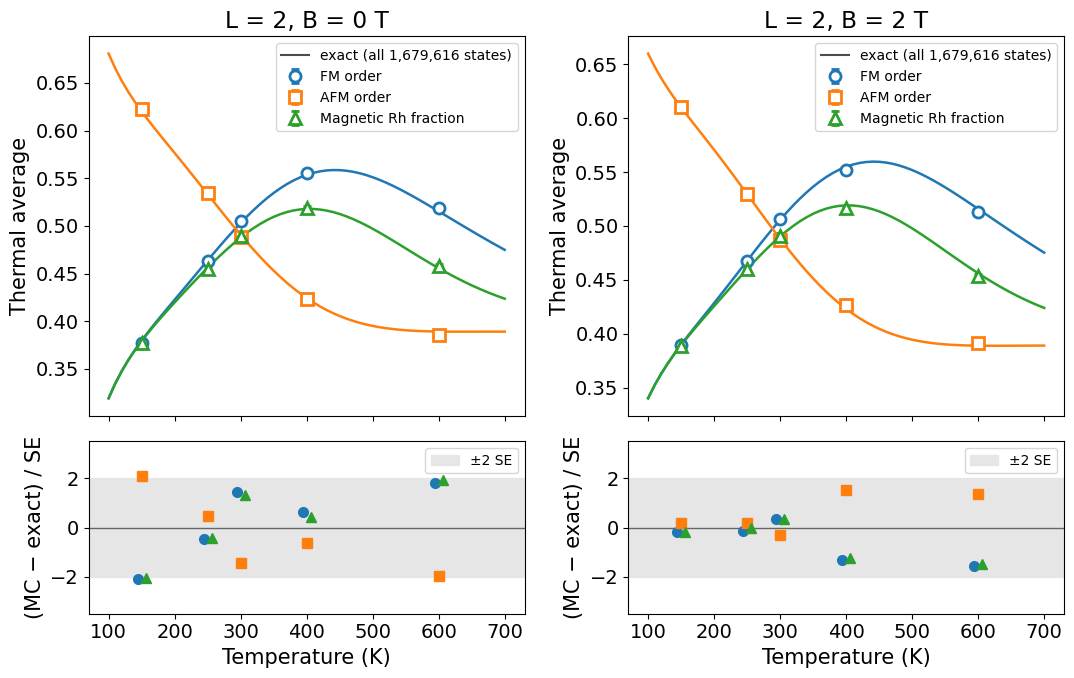

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1]})
labels = ["FM order", "AFM order", "Magnetic Rh fraction"]
markers = ["o", "s", "^"]
for col, B in enumerate(exact_fields):
    ax = axes[0, col]
    for q in range(3):
        ax.plot(T_fine, exact_curve[B][:, q], "-", color=f"C{q}", lw=1.8)
        ax.errorbar(T_mc, mc_mean[B][:, q], yerr=mc_se[B][:, q], fmt=markers[q], color=f"C{q}",
                    ms=8, mfc="white", mew=2, capsize=3, label=labels[q])
    ax.plot([], [], "-", color="0.3", label="exact (all 1,679,616 states)")
    ax.set(title=f"L = 2, B = {B:.0f} T", ylabel="Thermal average")
    ax.legend(fontsize=10)

    ax = axes[1, col]
    ax.axhspan(-2, 2, color="0.9", label="±2 SE")
    ax.axhline(0, color="0.4", lw=1)
    for q in range(3):
        z = (mc_mean[B][:, q] - exact_at_mc[B][:, q]) / mc_se[B][:, q]
        ax.plot(T_mc + (q - 1) * 6, z, markers[q], color=f"C{q}", ms=7)
    ax.set(xlabel="Temperature (K)", ylabel="(MC − exact) / SE", ylim=(-3.5, 3.5))
    ax.legend(fontsize=10, loc="upper right")
fig.tight_layout()
plt.savefig("figures/fig1_validation_exact.png", dpi=300, bbox_inches="tight")
plt.show()

**판정:** 위 그래프에서 Monte Carlo 점(속이 빈 표시)이 엄밀해 곡선 위에 놓이고, 아래 그래프에서 차이가 ±2 표준오차 띠 안에 들어오면 **통계적으로 일치**한다. 무작위 오차만 있다면 약 95%가 ±2 안에 들어오므로, 몇 개가 경계(±2) 근처에 있는 것은 정상이다. 또 같은 온도의 세 값($m_{FM}$, $m_{AF}$, Rh 분율)은 서로 연동돼 함께 움직이므로(위 그래프에서 세 표시가 같이 위아래로 움직임), 실제로 독립적인 비교는 "온도 5개 × 자기장 2개 = 10개"로 봐야 한다. 자기장이 있을 때($B=2$ T)도 일치하면, 자기장 항을 포함한 샘플링까지 올바르다는 뜻이다.

## Step 7. 본 계산: 온도 × 자기장 스캔

- 격자 $L=6$ (셀 216개), 온도 150–350 K를 5 K 간격으로
- 자기장 $B = 0$ – 3 T를 **0.25 T 간격**으로 (처음 버전의 0, 1, 2, 3 T로는 곡선 모양을 알 수 없어서 점을 늘림)
- 자기장마다 서로 다른 seed로 **독립 실행 10번** (5번으로는 0.25 T 간격의 변화보다 통계 잡음이 커서 늘림)
- 각 온도: 평형화 300 sweep, 그 뒤 2 sweep마다 측정해 1000개 표본

(일반 노트북에서 약 15–25분, 컴퓨터 상태에 따라 더 걸릴 수 있다. 결과는 `ferh_field_scan.npz`로 저장된다.)

In [8]:
L = 6
temperatures = np.arange(150.0, 351.0, 5.0)
fields = np.arange(0.0, 3.01, 0.25)              # Tesla: 0, 0.25, 0.5, ..., 3.0
seeds = [100, 300, 500, 700, 900, 1100, 1300, 1500, 1700, 1900]
N_EQUIL = 300       # 온도마다 버리는 평형화 sweep 수
N_SAMPLES = 1000    # 온도마다 모으는 표본 수

# scans[b, r, n, q]: 자기장 b, 실행 r, 온도 n, 측정량 q (0=FM, 1=AFM, 2=Rh분율)
scans = np.empty((len(fields), len(seeds), len(temperatures), 3))
T_t = np.empty((len(fields), len(seeds)))        # 실행마다 구한 전이온도

for b, B in enumerate(fields):
    for r, seed in enumerate(seeds):
        # seed: 실행(seed)과 자기장마다 겹치지 않는 난수 출발점 (온도 번호 0–40은 heating_scan 안에서 더해짐)
        scans[b, r] = heating_scan(L, temperatures, B, seed * 10000 + int(round(4 * B)) * 100,
                                   n_equil=N_EQUIL, n_samples=N_SAMPLES)
        T_t[b, r] = find_transition(temperatures, scans[b, r, :, 0], scans[b, r, :, 1])
    print(f"B = {B:4.2f} T: 실행별 T_t = {np.round(T_t[b], 1)} K")

np.savez("ferh_field_scan.npz", L=L, temperatures=temperatures, fields=fields,
         seeds=seeds, scans=scans, T_t=T_t)

B = 0.00 T: 실행별 T_t = [283.  282.8 293.6 285.4 288.  289.3 292.5 291.  286.  292. ] K


B = 0.25 T: 실행별 T_t = [288.3 290.7 290.6 293.4 295.8 294.7 281.4 275.  292.4 283.1] K


B = 0.50 T: 실행별 T_t = [282.4 296.8 289.3 287.2 280.  284.7 282.3 282.1 290.6 273.2] K


B = 0.75 T: 실행별 T_t = [277.  281.5 277.7 278.4 276.2 280.5 285.8 274.8 273.9 277.5] K


B = 1.00 T: 실행별 T_t = [266.9 277.8 276.9 275.3 272.1 267.7 264.  274.1 268.7 280.3] K


...

B = 2.00 T: 실행별 T_t = [252.5 247.8 239.  247.8 247.6 246.5 245.7 246.7 250.3 247.2] K


B = 2.25 T: 실행별 T_t = [230.8 233.4 234.6 240.2 238.4 237.3 241.3 233.7 233.6 228.9] K


B = 2.50 T: 실행별 T_t = [230.  227.1 219.3 226.9 232.4 223.  224.8 224.9 227.9 231.3] K


B = 2.75 T: 실행별 T_t = [217.4 221.5 214.  204.6 209.9 207.9 214.6 217.4 215.  217.5] K


B = 3.00 T: 실행별 T_t = [204.9 202.3 202.8 198.7 208.4 184.6 206.9 199.9 199.8 199.9] K


### Step 7-2. 실제 스핀 배열 들여다보기 (발표용 그림)

숫자만 보면 감이 안 오므로, 실제 시뮬레이션 배열의 한 층($k=0$)을 세 온도에서 그린다.
- 큰 화살표: Fe (빨강 = 위, 파랑 = 아래)
- 작은 표시: Rh (초록 화살표 = 모멘트 있음, 회색 점 = 모멘트 없음)

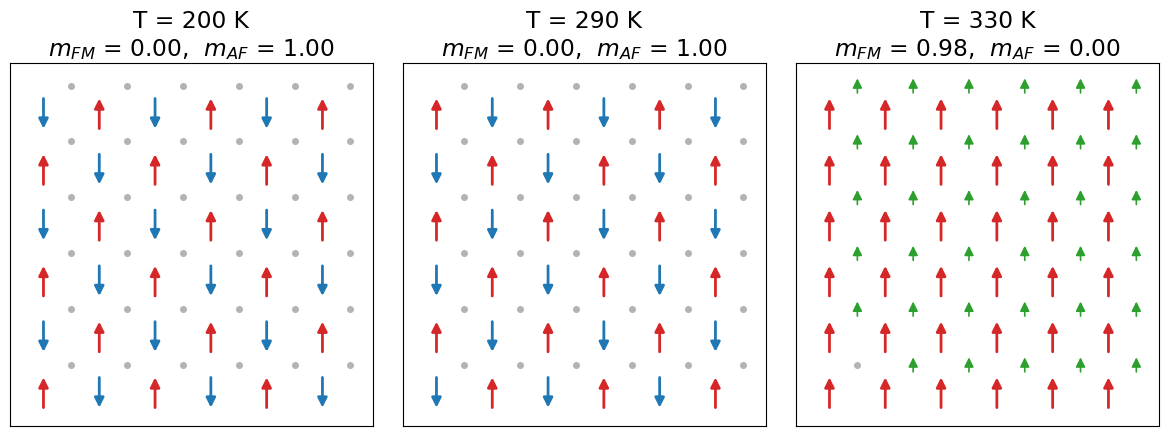

In [9]:
snap_temperatures = [200.0, 290.0, 330.0]
fe, rh = make_afm_state(L)
snapshots = {}
for n, T in enumerate(temperatures):
    measure_temperature(fe, rh, T, 0.0, 777000 + n, N_EQUIL, 50, 2)   # 데우면서 진행
    if T in snap_temperatures:
        snapshots[T] = (fe.copy(), rh.copy())                           # 그 순간의 배열 저장


def draw_layer(ax, fe, rh, k=0):
    L = fe.shape[0]
    for i in range(L):
        for j in range(L):
            # Fe: 격자점 (i, j)에 큰 화살표
            s = fe[i, j, k]
            color = "C3" if s > 0 else "C0"
            ax.annotate("", xy=(i, j + 0.32 * s), xytext=(i, j - 0.32 * s),
                        arrowprops=dict(arrowstyle="-|>", color=color, lw=2))
            # Rh: 입방체 중심 (i+0.5, j+0.5)에 작은 표시
            r = rh[i, j, k]
            if r == 0:
                ax.plot(i + 0.5, j + 0.5, "o", color="0.7", markersize=4)
            else:
                ax.annotate("", xy=(i + 0.5, j + 0.5 + 0.18 * r), xytext=(i + 0.5, j + 0.5 - 0.18 * r),
                            arrowprops=dict(arrowstyle="-|>", color="C2", lw=1.2))
    ax.set_xlim(-0.6, L - 0.1)
    ax.set_ylim(-0.6, L - 0.1)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, T in zip(axes, snap_temperatures):
    fe_s, rh_s = snapshots[T]
    m_fm, m_af, rh_frac = order_parameters(fe_s, rh_s)
    draw_layer(ax, fe_s, rh_s)
    ax.set_title(f"T = {T:.0f} K\n$m_{{FM}}$ = {m_fm:.2f},  $m_{{AF}}$ = {m_af:.2f}")
fig.tight_layout()
plt.savefig("figures/fig_snapshots.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 8. 결과 1: $B=0$에서 온도에 따른 자기 질서

낮은 온도: AFM 질서도 ≈ 1 → 온도가 오르면 FM 질서도가 커지고 Rh에 모멘트가 생김. Error bar는 10번 독립 실행의 표준오차.

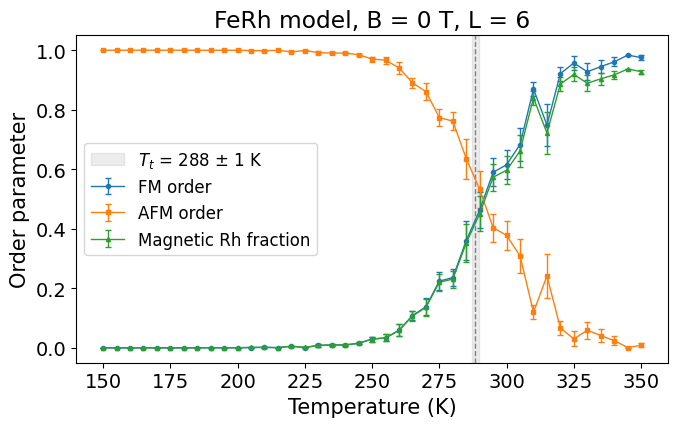

In [10]:
mean0 = scans[0].mean(axis=0)                                  # B=0, 실행 평균
se0 = scans[0].std(axis=0, ddof=1) / np.sqrt(len(seeds))       # 표준오차

fig, ax = plt.subplots(figsize=(7, 4.5))
labels = ["FM order", "AFM order", "Magnetic Rh fraction"]
markers = ["o", "s", "^"]
for q in range(3):
    ax.errorbar(temperatures, mean0[:, q], yerr=se0[:, q], fmt=markers[q] + "-",
                markersize=3, capsize=2, linewidth=1, label=labels[q])

Tt0_mean = np.nanmean(T_t[0])
Tt0_se = np.nanstd(T_t[0], ddof=1) / np.sqrt(np.sum(~np.isnan(T_t[0])))
ax.axvline(Tt0_mean, color="gray", linestyle="--", linewidth=1)
ax.axvspan(Tt0_mean - Tt0_se, Tt0_mean + Tt0_se, color="gray", alpha=0.15,
           label=f"$T_t$ = {Tt0_mean:.0f} ± {Tt0_se:.0f} K")
ax.set(xlabel="Temperature (K)", ylabel="Order parameter",
       title=f"FeRh model, B = 0 T, L = {L}")
ax.set_ylim(-0.05, 1.05)
ax.legend()
fig.tight_layout()
plt.savefig("figures/fig2_order_vs_T.png", dpi=300, bbox_inches="tight")
plt.show()

### Step 8-2. 자기장마다의 질서도 곡선 (발표 백업용)

결과 2에서 쓰는 $T_t$ 13개가 각각 어떤 곡선에서 나왔는지 확인할 수 있도록, 자기장마다 질서도 곡선을 따로 그린다. 세로 점선이 그 자기장의 $T_t$(10번 실행 평균)다.

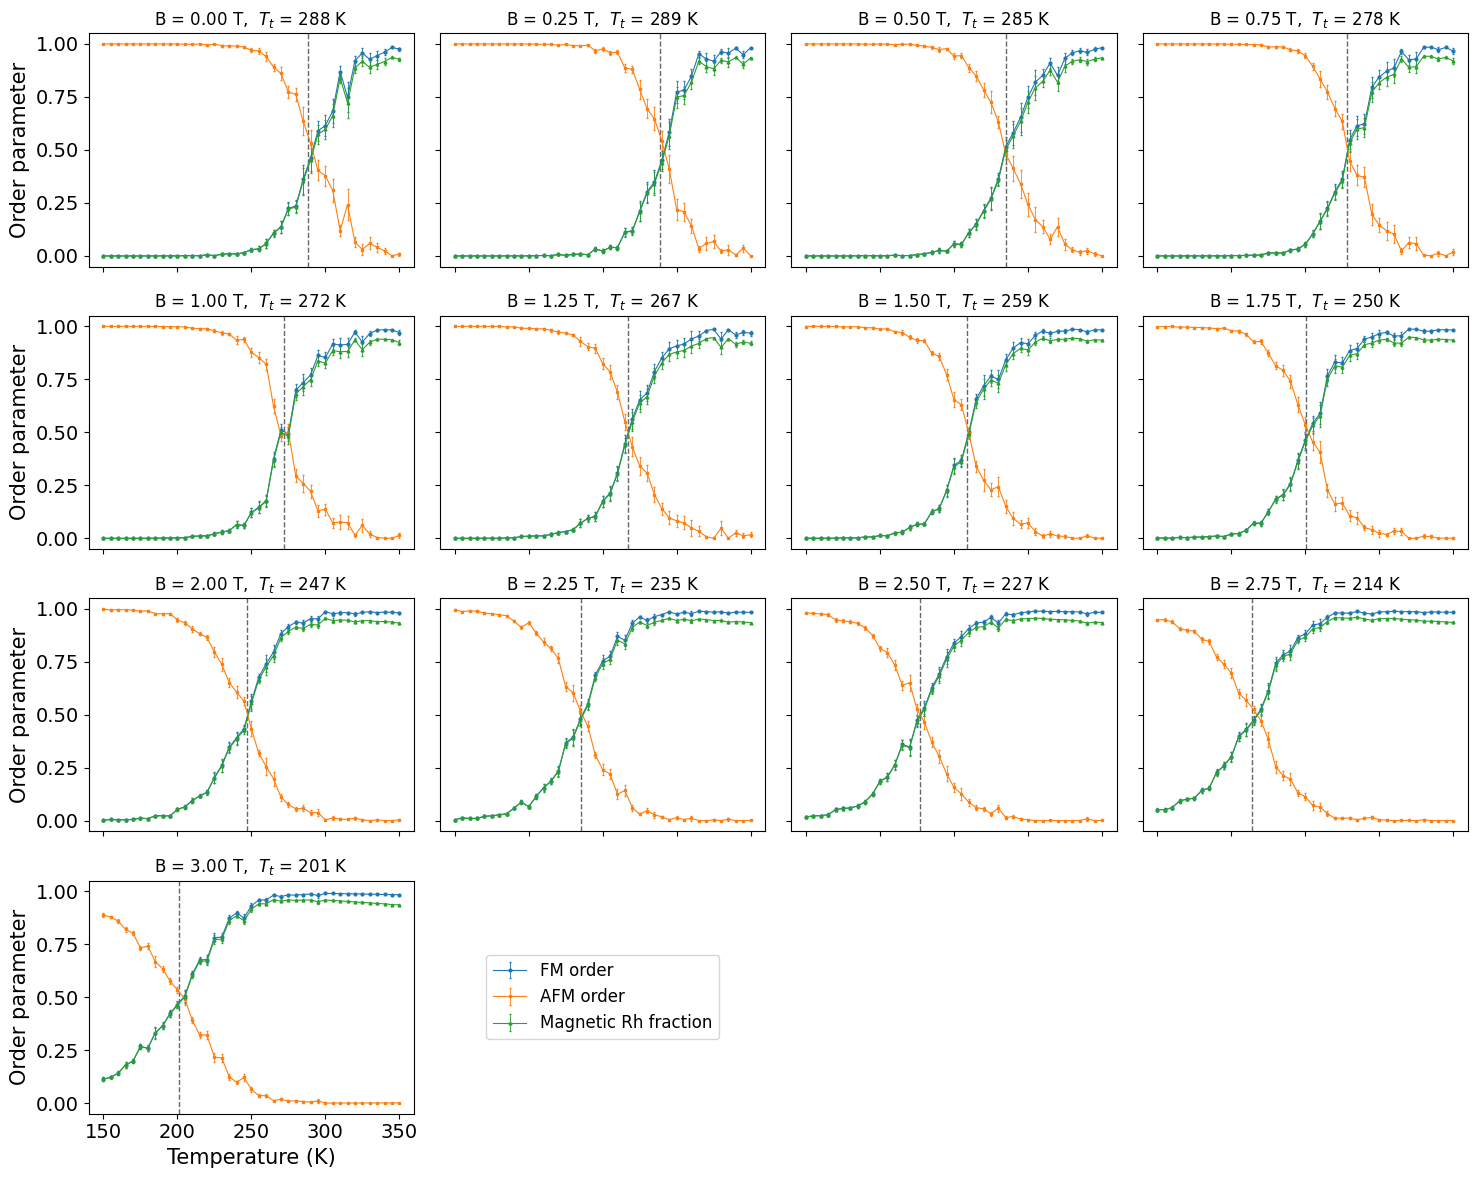

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(15, 12), sharex=True, sharey=True)
labels = ["FM order", "AFM order", "Magnetic Rh fraction"]
markers = ["o", "s", "^"]
for b, B in enumerate(fields):
    ax = axes.flat[b]
    mean_b = scans[b].mean(axis=0)
    se_b = scans[b].std(axis=0, ddof=1) / np.sqrt(len(seeds))
    for q in range(3):
        ax.errorbar(temperatures, mean_b[:, q], yerr=se_b[:, q], fmt=markers[q] + "-",
                    ms=2, lw=0.8, elinewidth=0.6, capsize=1, label=labels[q])
    Tt_b = np.nanmean(T_t[b])
    ax.axvline(Tt_b, color="0.4", ls="--", lw=1)
    ax.set_title(f"B = {B:.2f} T,  $T_t$ = {Tt_b:.0f} K", fontsize=12)
for ax in axes.flat[len(fields):]:
    ax.axis("off")
axes.flat[len(fields)].legend(*axes.flat[0].get_legend_handles_labels(), loc="center", fontsize=12)
for ax in axes[-1]:
    ax.set_xlabel("Temperature (K)")
for ax in axes[:, 0]:
    ax.set_ylabel("Order parameter")
fig.tight_layout()
plt.savefig("figures/fig_order_all_fields.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 9. 결과 2: 자기장에 따른 전이온도 — 직선인가?

처음 버전에서는 0, 1, 2 T 세 점에 직선을 맞춰 기울기를 구했다. 그런데 $T_t(B)$가 정말 직선인지 확인하지 않았다. 그래서 자기장을 0.25 T 간격으로 늘린 데이터로 **구간 기울기**를 계산했다. 직선이라면 어느 구간에서 재든 기울기가 같아야 한다.

0.25 T 간격의 이웃한 두 점만 쓰면 통계 잡음이 기울기를 크게 흔든다. 그래서 **폭 1 T 구간(점 5개)에 직선을 맞춘 기울기**를 0.25 T씩 옮겨 가며 구했다. 실행마다 따로 구한 뒤 평균 ± 표준오차를 냈다.

 B (T) | T_t 평균 ± SE (K)
  0.00 |  288.4 ± 1.2
  0.25 |  288.6 ± 2.1
  0.50 |  284.9 ± 2.1
  0.75 |  278.3 ± 1.1
  1.00 |  272.4 ± 1.7
  1.25 |  266.8 ± 1.1
  1.50 |  258.6 ± 1.0
  1.75 |  250.2 ± 1.3
  2.00 |  247.1 ± 1.1
  2.25 |  235.2 ± 1.3
  2.50 |  226.8 ± 1.3
  2.75 |  214.0 ± 1.6
  3.00 |  200.8 ± 2.1

 구간 (T)     | 구간 기울기 (K/T)
 0.00 – 1.00 |  -16.9 ± 1.6
 0.25 – 1.25 |  -22.4 ± 2.9
 0.50 – 1.50 |  -25.6 ± 1.8
 0.75 – 1.75 |  -28.0 ± 1.2
 1.00 – 2.00 |  -26.9 ± 2.2
 1.25 – 2.25 |  -29.9 ± 1.7
 1.50 – 2.50 |  -31.4 ± 1.3
 1.75 – 2.75 |  -37.1 ± 1.6
 2.00 – 3.00 |  -45.5 ± 2.2


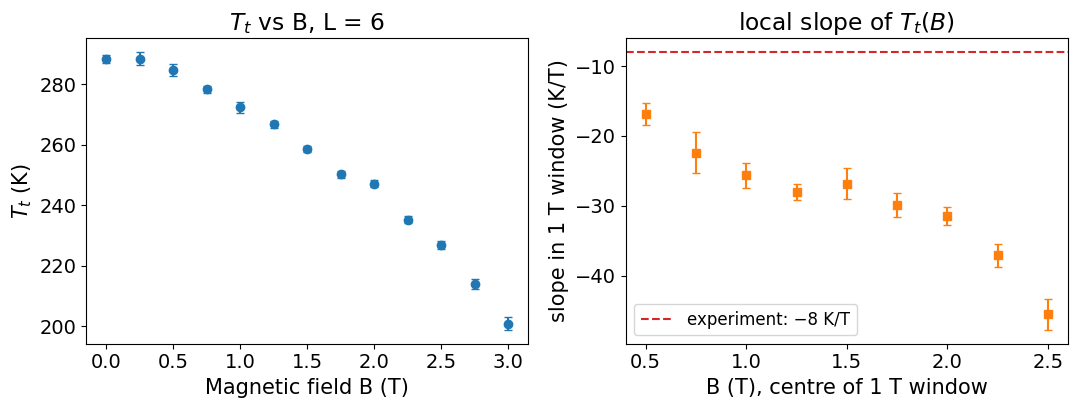

In [12]:
Tt_mean = np.nanmean(T_t, axis=1)
Tt_se = np.nanstd(T_t, axis=1, ddof=1) / np.sqrt(np.sum(~np.isnan(T_t), axis=1))
EXP_SLOPE = -8.0   # K/T, Maat et al. (2005)

print(" B (T) | T_t 평균 ± SE (K)")
for B, m, e in zip(fields, Tt_mean, Tt_se):
    print(f"{B:6.2f} | {m:6.1f} ± {e:.1f}")

# 구간 기울기: 폭 1 T(점 5개) 구간에 실행마다 직선을 맞추고, 그 기울기들의 평균 ± SE
window = 4                       # 0.25 T 간격 4칸 = 1 T 폭
print("\n 구간 (T)     | 구간 기울기 (K/T)")
B_mid = []
seg_mean = []
seg_se = []
for b in range(len(fields) - window):
    part = slice(b, b + window + 1)
    seg = [np.polyfit(fields[part], T_t[part, r], 1)[0] for r in range(len(seeds))]
    B_mid.append(fields[b] + 0.5 * window * (fields[1] - fields[0]))
    seg_mean.append(np.mean(seg))
    seg_se.append(np.std(seg, ddof=1) / np.sqrt(len(seg)))
    print(f" {fields[b]:4.2f} – {fields[b + window]:4.2f} | {seg_mean[-1]:6.1f} ± {seg_se[-1]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].errorbar(fields, Tt_mean, yerr=Tt_se, fmt="o", color="C0", capsize=3)
axes[0].set(xlabel="Magnetic field B (T)", ylabel="$T_t$ (K)", title=f"$T_t$ vs B, L = {L}")
axes[1].errorbar(B_mid, seg_mean, yerr=seg_se, fmt="s", color="C1", capsize=3)
axes[1].axhline(EXP_SLOPE, color="C3", ls="--", label="experiment: −8 K/T")
axes[1].set(xlabel="B (T), centre of 1 T window", ylabel="slope in 1 T window (K/T)",
            title="local slope of $T_t(B)$")
axes[1].legend()
fig.tight_layout()
plt.savefig("figures/fig3a_Tt_vs_B_data.png", dpi=300, bbox_inches="tight")
plt.show()

**관찰:** 구간 기울기가 자기장에 따라 크게 변한다. 낮은 자기장에서는 완만하고, 높은 자기장에서는 가파르다. 즉 $T_t(B)$는 **직선이 아니다.** 그래서 0–2 T 직선으로 맞춘 기울기 하나를 결과로 쓰는 것은 타당하지 않다고 판단했다.

다항식(예: 2차식)으로 맞춰서 $B=0$의 기울기를 구하는 방법도 있지만, 왜 휘는지 모르는 채로 맞추면 숫자의 의미를 설명할 수 없다. 그래서 **휘어짐의 원인을 먼저 찾기로 했다** (Step 12–13). 그 전에 격자 크기(Step 10)와 평형화 길이(Step 11)를 바꿔도 결과가 유지되는지 확인한다.

## Step 10. 검증 3: 격자 크기와 가열/냉각 방향을 바꾸면?

Step 9의 결과가 **작은 격자 때문에 생긴 착시**일 수도 있다. 그래서 두 가지를 바꿔 다시 계산한다.

1. **격자 크기** $L = 4, 6, 8$: $L$은 물리 조건이 아니라 **무한한 결정을 흉내 내는 계산 상자의 크기**다. 결과가 $L$에 따라 어떻게 변하는지 봐야 무한 결정의 값을 추정할 수 있다.
2. **가열 vs 냉각**: AFM에서 시작해 데우는 경우와 FM에서 시작해 식히는 경우의 $T_t$가 다르면, 계산이 한 상태에 **갇혀 있다**(히스테리시스)는 뜻이다.

자기장은 0, 1, 2 T를 쓰고, 온도 범위는 400 K까지 넓혔다. 크기별 비교를 위해 0–2 T 직선 기울기를 같은 방식으로 구했다(절대값이 아니라 **크기에 따른 변화**를 보려는 것).

**실행 시간:** $L=8$을 가열·냉각 모두 계산해서 **약 15분**(컴퓨터 상태에 따라 최대 40분) 걸린다. 그래서 기본값은 **저장된 결과(`ferh_size_check.npz`)를 불러오기**다. 다시 계산하려면 아래 셀의 `RUN_SIZE_CHECK = True`로 바꾼다. seed가 고정돼 있어 다시 계산해도 같은 숫자가 나온다.

In [13]:
def cooling_scan(L, temperatures, B, seed, n_equil=300, n_samples=300, stride=2):
    # FM(모든 스핀 +1)에서 시작해 높은 온도 → 낮은 온도로 차례로 식힘
    fe = np.ones((L, L, L), dtype=np.int8)
    rh = np.ones((L, L, L), dtype=np.int8)
    results = np.empty((len(temperatures), 3))
    for n in range(len(temperatures) - 1, -1, -1):     # 마지막(가장 높은) 온도부터 거꾸로
        results[n] = measure_temperature(fe, rh, temperatures[n], B, seed + n, n_equil, n_samples, stride)
    return results


RUN_SIZE_CHECK = False   # True: 약 15분 걸려 다시 계산 / False: 저장된 결과 불러오기

size_temperatures = np.arange(150.0, 401.0, 5.0)
size_fields = np.array([0.0, 1.0, 2.0])
size_cases = [(4, "heating"), (6, "heating"), (6, "cooling"), (8, "heating"), (8, "cooling")]
size_seeds = seeds[:5]   # 계산량 때문에 크기 검증은 독립 실행 5번

size_Tt = {}        # (L, 방향) → T_t 배열 [자기장, 실행]
size_slopes = {}    # (L, 방향) → 실행별 0–2 T 직선 기울기

if RUN_SIZE_CHECK or not os.path.exists("ferh_size_check.npz"):
    # ----- 직접 계산 -----
    for L_check, direction in size_cases:
        Tt_case = np.empty((len(size_fields), len(size_seeds)))
        for b, B in enumerate(size_fields):
            for r, seed in enumerate(size_seeds):
                if direction == "heating":
                    res = heating_scan(L_check, size_temperatures, B, seed * 1000 + b * 100,
                                       n_equil=N_EQUIL, n_samples=N_SAMPLES)
                else:
                    res = cooling_scan(L_check, size_temperatures, B, seed * 1000 + b * 100,
                                       n_equil=N_EQUIL, n_samples=N_SAMPLES)
                Tt_case[b, r] = find_transition(size_temperatures, res[:, 0], res[:, 1])
        size_Tt[(L_check, direction)] = Tt_case
    np.savez("ferh_size_check.npz", size_temperatures=size_temperatures, size_fields=size_fields,
             cases=np.array([f"L{L_check}_{d}" for L_check, d in size_cases]),
             Tt=np.array([size_Tt[c] for c in size_cases]))
    print("격자 크기 검증을 새로 계산해서 ferh_size_check.npz에 저장했다.")
else:
    # ----- 저장된 결과 불러오기 -----
    saved = np.load("ferh_size_check.npz")
    for case, Tt_case in zip(size_cases, saved["Tt"]):
        size_Tt[case] = Tt_case
    print("저장된 격자 크기 검증 결과(ferh_size_check.npz)를 불러왔다. 다시 계산하려면 RUN_SIZE_CHECK = True")

for case, Tt_case in size_Tt.items():
    size_slopes[case] = [np.polyfit(size_fields, Tt_case[:, r], 1)[0] for r in range(Tt_case.shape[1])]

print(" L | 방향    | T_t(B=0) 실행별 (K)                 | T_t(B=0) 평균 ± SE | 0–2 T 기울기 평균 ± SE (K/T)")
for (L_check, direction), Tt_case in size_Tt.items():
    s_ = np.array(size_slopes[(L_check, direction)])
    n = Tt_case.shape[1]
    print(f"{L_check:2d} | {direction:7s} | {np.round(Tt_case[0], 1)} | "
          f"{Tt_case[0].mean():6.1f} ± {Tt_case[0].std(ddof=1)/np.sqrt(n):4.1f}  | "
          f"{s_.mean():6.1f} ± {s_.std(ddof=1)/np.sqrt(n):4.1f}")

저장된 격자 크기 검증 결과(ferh_size_check.npz)를 불러왔다. 다시 계산하려면 RUN_SIZE_CHECK = True
 L | 방향    | T_t(B=0) 실행별 (K)                 | T_t(B=0) 평균 ± SE | 0–2 T 기울기 평균 ± SE (K/T)
 4 | heating | [284.1 289.3 297.2 292.9 288.9] |  290.5 ±  2.2  |  -16.9 ±  0.6
 6 | heating | [290.8 295.3 287.6 292.1 287.5] |  290.7 ±  1.5  |  -22.3 ±  0.5
 6 | cooling | [278.6 292.3 289.2 278.6 288.8] |  285.5 ±  2.9  |  -19.8 ±  1.3
 8 | heating | [272.5 322.5 282.3 284.8 297.7] |  292.0 ±  8.6  |  -28.6 ±  3.9
 8 | cooling | [293.3 271.2 287.5 287.3 272.3] |  282.3 ±  4.5  |  -23.2 ±  1.8


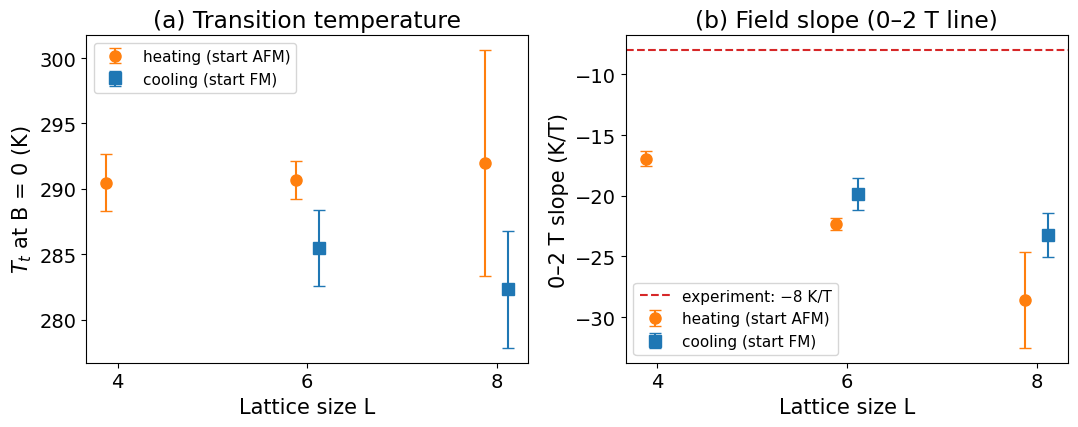

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
style = {"heating": dict(fmt="o", color="C1", label="heating (start AFM)"),
         "cooling": dict(fmt="s", color="C0", label="cooling (start FM)")}
shift = {"heating": -0.12, "cooling": 0.12}       # 두 점이 겹치지 않게 좌우로 살짝 옮김
n = len(size_seeds)

for direction in ["heating", "cooling"]:
    Ls = [Lc for Lc, d in size_cases if d == direction]
    x = np.array(Ls) + shift[direction]
    Tt0 = [size_Tt[(Lc, direction)][0].mean() for Lc in Ls]
    Tt0_se = [size_Tt[(Lc, direction)][0].std(ddof=1) / np.sqrt(n) for Lc in Ls]
    sl = [np.mean(size_slopes[(Lc, direction)]) for Lc in Ls]
    sl_se = [np.std(size_slopes[(Lc, direction)], ddof=1) / np.sqrt(n) for Lc in Ls]
    ax1.errorbar(x, Tt0, yerr=Tt0_se, markersize=8, capsize=4, **style[direction])
    ax2.errorbar(x, sl, yerr=sl_se, markersize=8, capsize=4, **style[direction])

ax2.axhline(EXP_SLOPE, color="C3", linestyle="--", label="experiment: −8 K/T")
ax1.set(xlabel="Lattice size L", ylabel="$T_t$ at B = 0 (K)", xticks=[4, 6, 8],
        title="(a) Transition temperature")
ax2.set(xlabel="Lattice size L", ylabel="0–2 T slope (K/T)", xticks=[4, 6, 8],
        title="(b) Field slope (0–2 T line)")
ax1.legend(fontsize=11)
ax2.legend(fontsize=11)
fig.tight_layout()
plt.savefig("figures/fig4_size_check.png", dpi=300, bbox_inches="tight")
plt.show()

**격자 크기 검증 결과 읽는 법**

- **$T_t(B=0)$:** $L=4, 6, 8$ 모두 약 282–292 K로 크게 다르지 않다.
- **가열과 냉각:** $L=6$에서 두 방법의 $T_t$ 차이는 약 5 K로 오차 막대 2개 정도 안이다. 평형에 거의 도달했다.
- **$L=8$ 가열은 믿기 어렵다.** 일부 실행이 AFM에 **갇혀** 훨씬 높은 온도까지 머물렀다(과열). 큰 격자에서는 집단 이동이 잘 채택되지 않아 생기는 문제이고, 본 계산에 $L=6$을 쓴 이유다.
- **0–2 T 기울기가 $L$이 커질수록 가팔라진다** (약 −17 → −22 → −23 K/T). 즉 이 기울기는 격자 크기에 의존한다. 이 의존성의 원인은 Step 13에서 설명한다(낮은 자기장에서의 작은 격자 효과).

**엄밀해 비교는 왜 $L=2$에서만?** 모든 배열을 더하는 방법은 $L=2$($1.7\times10^6$개)까지만 가능하고 $L=6$은 약 $10^{168}$개라 불가능하다. 대신 같은 $L=6$에서는 에너지 검사(Step 3)와 이 검사로 보완했다.

## Step 11. 검증 4: 평형화 길이(sweep 수)를 바꿔도 $T_t$가 같은가?

온도마다 버리는 평형화 sweep 수(`N_EQUIL`)가 부족하면, 결과가 "얼마나 빨리 데웠는가"에 따라 달라진다. 그래서 `N_EQUIL`을 100, 300(본 계산), 1000으로 바꿔 $B=0$의 $T_t$를 비교한다. **충분하다면 세 값이 오차 범위 안에서 같아야 한다.**

**실행 시간:** 약 3분(컴퓨터 상태에 따라 최대 8분). 기본값은 저장된 결과(`ferh_equil_check.npz`) 불러오기이고, 파일이 없으면 새로 계산한다. 다시 계산하려면 `RUN_EQUIL_CHECK = True`로 바꾼다.

주의: MC의 sweep은 실제 시간이 아니므로, MC에서 보이는 히스테리시스 크기를 실험의 열적 히스테리시스(약 10 K)와 직접 비교하지 않는다. 우리가 구하는 것은 **평형 상태의 $T_t$**다.

In [15]:
RUN_EQUIL_CHECK = False   # True: 약 3분 걸려 다시 계산 / False: 저장된 결과 불러오기

equil_options = [100, 300, 1000]
Tt_equil = {}
if RUN_EQUIL_CHECK or not os.path.exists("ferh_equil_check.npz"):
    # ----- 직접 계산 -----
    for n_eq in equil_options:
        if n_eq == N_EQUIL:
            Tt_equil[n_eq] = T_t[0]          # 300은 본 계산(Step 7)의 B=0 결과를 그대로 사용
            continue
        values = []
        for seed in seeds:
            res = heating_scan(L, temperatures, 0.0, seed * 10000, n_equil=n_eq, n_samples=N_SAMPLES)
            values.append(find_transition(temperatures, res[:, 0], res[:, 1]))
        Tt_equil[n_eq] = np.array(values)
    np.savez("ferh_equil_check.npz", equil_options=equil_options,
             Tt=np.array([Tt_equil[n] for n in equil_options]))
    print("평형화 길이 검증을 새로 계산해서 ferh_equil_check.npz에 저장했다.")
else:
    # ----- 저장된 결과 불러오기 -----
    saved = np.load("ferh_equil_check.npz")
    for n_eq, values in zip(saved["equil_options"], saved["Tt"]):
        Tt_equil[int(n_eq)] = values
    print("저장된 평형화 길이 검증 결과(ferh_equil_check.npz)를 불러왔다. 다시 계산하려면 RUN_EQUIL_CHECK = True")

for n_eq in equil_options:
    v = Tt_equil[n_eq]
    print(f"N_EQUIL = {n_eq:4d} sweep:  T_t(B=0) = {v.mean():.1f} ± {v.std(ddof=1)/np.sqrt(len(v)):.1f} K   (실행별 {np.round(v, 1)})")

저장된 평형화 길이 검증 결과(ferh_equil_check.npz)를 불러왔다. 다시 계산하려면 RUN_EQUIL_CHECK = True
N_EQUIL =  100 sweep:  T_t(B=0) = 287.7 ± 1.8 K   (실행별 [283.8 283.2 287.6 278.4 289.5 291.1 290.7 292.  283.5 297.6])
N_EQUIL =  300 sweep:  T_t(B=0) = 288.4 ± 1.2 K   (실행별 [283.  282.8 293.6 285.4 288.  289.3 292.5 291.  286.  292. ])
N_EQUIL = 1000 sweep:  T_t(B=0) = 288.1 ± 1.4 K   (실행별 [284.2 283.8 291.5 287.  287.9 284.  288.3 284.9 297.4 292.2])


## Step 12. Clausius–Clapeyron: $B=0$에서 측정한 값으로 기울기 예측

1차 전이에서는 **Clausius–Clapeyron 관계**가 성립한다:
$$\frac{dT_t}{dB}=-\frac{\Delta M}{\Delta S},\qquad \Delta S=\frac{\Delta U}{T_t}$$
- $\Delta M$: FM과 AFM 상태의 자화 차이 (셀 하나당, $\mu_B$)
- $\Delta U$: 두 상태의 평균 에너지 차이 (= 전이에 필요한 잠열)
- $\Delta S$: 두 상태의 엔트로피 차이. $T_t$에서는 두 상태의 자유에너지 $F=U-TS$가 같으므로 $\Delta U = T_t\,\Delta S$이다.

**계산 방법:** $B=0$, $T=T_t$에서 오래 시뮬레이션하면 작은 격자는 AFM과 FM 사이를 계속 오간다. 매 표본마다 $m_{FM}>m_{AF}$이면 "FM 상태", 아니면 "AFM 상태"로 분류하고, 각 상태의 평균 에너지와 평균 자화를 따로 구한다. 그 차이로 $\Delta U$, $\Delta M$ → $\Delta S$ → **예측 기울기**를 계산한다.

이 기울기는 **무한히 큰 결정**에서 자기장이 작을 때의 기울기에 해당한다. 실험(큰 시료, 낮은 자기장의 직선 구간)과 비교할 값은 바로 이것이다.

In [16]:
@njit
def phase_resolved_averages(fe, rh, T, B, seed, n_equil, n_samples):
    # 반환: [상태(0=AFM, 1=FM), (표본 수, 에너지 합, |자화| 합)]
    np.random.seed(seed)
    N_cell = fe.shape[0] ** 3
    for _ in range(n_equil):
        mc_sweep(fe, rh, T, B)
    totals = np.zeros((2, 3))
    for _ in range(n_samples):
        for _ in range(2):
            mc_sweep(fe, rh, T, B)
        m_fm, m_af, rh_fraction = order_parameters(fe, rh)
        energy = total_energy(fe, rh, B) / N_cell                              # 셀당 에너지 (mRy)
        magnet = abs(MU_FE * fe.sum() + MU_RH * rh.sum()) / N_cell             # 셀당 |자화| (mu_B)
        phase = 1 if m_fm > m_af else 0
        totals[phase, 0] += 1
        totals[phase, 1] += energy
        totals[phase, 2] += magnet
    return totals


T_cc = round(Tt_mean[0])          # B=0 전이온도 근처에서 계산
cc_runs = []
for seed in seeds:
    fe, rh = make_afm_state(L)
    t = phase_resolved_averages(fe, rh, T_cc, 0.0, seed + 42, 1000, 20000)
    fm_fraction = t[1, 0] / (t[0, 0] + t[1, 0])
    dU = t[1, 1] / t[1, 0] - t[0, 1] / t[0, 0]          # mRy
    dM = t[1, 2] / t[1, 0] - t[0, 2] / t[0, 0]          # mu_B
    dS = dU / T_cc                                       # mRy/K
    predicted_slope = -dM * MUB_MRY_PER_T / dS           # K/T
    cc_runs.append([fm_fraction, dU, dM, dS / KB_MRY_PER_K, predicted_slope])
cc_runs = np.array(cc_runs)
cc_mean = cc_runs.mean(axis=0)
cc_se = cc_runs.std(axis=0, ddof=1) / np.sqrt(len(seeds))

names = ["FM 상태 비율", "ΔU (mRy/셀)", "ΔM (μB/셀)", "ΔS (kB/셀)", "예측 기울기 (K/T)"]
for name, m, e in zip(names, cc_mean, cc_se):
    print(f"{name:14s}: {m:8.3f} ± {e:.3f}")

# 실험 기울기(-8 K/T)를 내려면 엔트로피가 얼마여야 하나? (ΔM은 그대로 둠)
dS_needed = cc_mean[2] * MUB_MRY_PER_T / (-EXP_SLOPE) / KB_MRY_PER_K
print(f"\nT = {T_cc} K에서 계산")
print(f"무한 결정의 기울기 (Clausius–Clapeyron) = {cc_mean[4]:.1f} ± {cc_se[4]:.1f} K/T,  실험 = {EXP_SLOPE:.0f} K/T")
print(f"실험 −8 K/T에 필요한 ΔS = {dS_needed:.2f} kB/셀  →  모델 ΔS의 {dS_needed / cc_mean[3]:.1f}배")

# 단위 바꾸기: k_B/f.u. → J/(kg K). FeRh 한 단위의 몰질량 = 55.845 + 102.906 = 158.751 g/mol
R_GAS = 8.314462618          # J/(mol K)
MOLAR_MASS = 0.158751        # kg/mol
print(f"모델 ΔS = {cc_mean[3] * R_GAS / MOLAR_MASS:.1f} J/(kg K)   (Gruner 등이 보고한 이 모델의 값: 5.2 J/(kg K), 실험의 30–45%)")

np.savez("ferh_clausius_clapeyron.npz", T_cc=T_cc, runs=cc_runs, dS_needed=dS_needed)

FM 상태 비율      :    0.434 ± 0.010
ΔU (mRy/셀)    :    0.209 ± 0.000
ΔM (μB/셀)     :    4.055 ± 0.000
ΔS (kB/셀)     :    0.115 ± 0.000
예측 기울기 (K/T)  :  -23.717 ± 0.055

T = 288 K에서 계산
무한 결정의 기울기 (Clausius–Clapeyron) = -23.7 ± 0.1 K/T,  실험 = -8 K/T
실험 −8 K/T에 필요한 ΔS = 0.34 kB/셀  →  모델 ΔS의 3.0배
모델 ΔS = 6.0 J/(kg K)   (Gruner 등이 보고한 이 모델의 값: 5.2 J/(kg K), 실험의 30–45%)


## Step 13. 왜 $T_t(B)$가 휘어지는가? — 유한 격자 효과를 식으로 확인

Step 9에서 본 곡선은 **낮은 자기장에서 완만하고, 높은 자기장에서 가파르다.** 원인을 두 가지로 생각했다.

**(1) 낮은 자기장: 작은 격자 효과.** 자기장이 0이면 FM에는 "모두 위"와 "모두 아래" 두 방향이 있고 똑같이 유리하다. 큰 결정에서는 아주 약한 자기장만 걸어도 "위" FM만 남는다. 하지만 원자가 216개뿐인 작은 격자에서는 자기장이 약하면 "아래" FM도 꽤 섞여 있어서, 자기장의 이득을 다 받지 못한다. 이 효과를 넣으면 FM의 자유에너지는
$$F_{FM}(B)=F_{FM}(0)-k_BT\ln\cosh\!\left(\frac{M B}{k_BT}\right)\quad(M=\text{격자 전체의 자화 차이}\times\mu_B)$$
이고, 전이 조건 $F_{FM}=F_{AFM}$은
$$N\Delta U - T\,N\Delta S - k_BT\ln\cosh\!\left(\frac{MB}{k_BT}\right)=0 .$$
자기장이 충분히 커서 $MB\gg k_BT$이면 $\ln\cosh x\approx x-\ln2$가 되어, 기울기가 Clausius–Clapeyron 값 $-\Delta M/\Delta S$로 돌아간다. 격자가 클수록($M$이 클수록) 이 완만한 구간이 좁아진다. Step 10에서 0–2 T 기울기가 $L$이 커질수록 가팔라진 것도 이것으로 설명된다.

**(2) 높은 자기장: 모델 자체의 특성.** $T_t$가 291 K에서 많이 내려가면, 그 온도에서의 $\Delta U$, $\Delta S$가 291 K에서 잰 값과 달라진다. 아래 식은 $\Delta U$, $\Delta S$를 Step 12의 값으로 고정했으므로 높은 자기장에서는 시뮬레이션과 어긋날 것으로 예상했다.

**이 식에는 맞춤 매개변수가 하나도 없다.** $\Delta U$, $\Delta S$, $\Delta M$은 모두 Step 12에서 $B=0$으로 측정한 값이다.

무한 결정의 기울기 = -23.7 K/T  (Step 12와 같은 값)

 B (T) | 시뮬레이션 T_t (K) | 유한 격자 식 (K) | (시뮬−식)/SE | 무한 결정 직선 (K)
  0.00 |   288.4 ± 1.2      |   288.0          |   +0.3       |   288.0
  0.25 |   288.6 ± 2.1      |   286.5          |   +0.9       |   282.1
  0.50 |   284.9 ± 2.1      |   282.7          |   +1.0       |   276.1
  0.75 |   278.3 ± 1.1      |   277.5          |   +0.7       |   270.2
  1.00 |   272.4 ± 1.7      |   271.7          |   +0.4       |   264.3
  1.25 |   266.8 ± 1.1      |   265.7          |   +1.0       |   258.4
  1.50 |   258.6 ± 1.0      |   259.7          |   -1.0       |   252.4
  1.75 |   250.2 ± 1.3      |   253.6          |   -2.7       |   246.5
  2.00 |   247.1 ± 1.1      |   247.5          |   -0.3       |   240.6
  2.25 |   235.2 ± 1.3      |   241.4          |   -4.9       |   234.6
  2.50 |   226.8 ± 1.3      |   235.3          |   -6.8       |   228.7
  2.75 |   214.0 ± 1.6      |   229.2          |   -9.4       |   222.8
  3.00 |   200.8 ± 2.1      |  

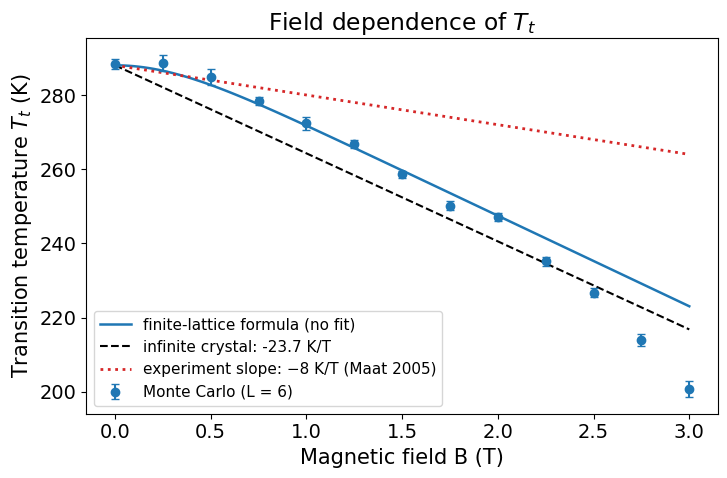

In [17]:
# Step 12에서 B = 0으로 측정한 값 (격자 전체)
N_cell = L ** 3
dU_tot = N_cell * cc_mean[1]                       # mRy
dS_tot = N_cell * cc_mean[3] * KB_MRY_PER_K        # mRy/K
M_tot = N_cell * cc_mean[2] * MUB_MRY_PER_T        # mRy/T


def Tt_infinite(B):
    # 무한 결정: Clausius–Clapeyron 직선
    return (dU_tot - M_tot * B) / dS_tot


def Tt_finite(B):
    # 유한 격자: FM의 위/아래 두 방향을 고려한 전이 조건을 이분법으로 푼다
    def dF(T):
        x = M_tot * B / (KB_MRY_PER_K * T)
        return dU_tot - T * dS_tot - KB_MRY_PER_K * T * np.log(np.cosh(x))
    lo, hi = 50.0, 400.0
    for _ in range(100):
        mid = 0.5 * (lo + hi)
        if dF(lo) * dF(mid) <= 0:
            hi = mid
        else:
            lo = mid
    return 0.5 * (lo + hi)


slope_infinite = -M_tot / dS_tot
print(f"무한 결정의 기울기 = {slope_infinite:.1f} K/T  (Step 12와 같은 값)\n")
print(" B (T) | 시뮬레이션 T_t (K) | 유한 격자 식 (K) | (시뮬−식)/SE | 무한 결정 직선 (K)")
for B, m, e in zip(fields, Tt_mean, Tt_se):
    fin = Tt_finite(B)
    print(f"{B:6.2f} | {m:7.1f} ± {e:3.1f}      | {fin:7.1f}          | {(m - fin) / e:+6.1f}       | {Tt_infinite(B):7.1f}")

# 참고: 다항식으로 맞춘 B=0 기울기 (휘어짐의 원인을 모른 채 맞추면 어떤 값이 나오는지)
quad_slopes = [np.polyfit(fields, T_t[:, r], 2)[1] for r in range(len(seeds))]
print(f"\n참고: 2차식 맞춤의 B=0 기울기 = {np.mean(quad_slopes):.1f} ± {np.std(quad_slopes, ddof=1)/np.sqrt(len(seeds)):.1f} K/T"
      "  (작은 격자 효과를 따라간 값이라 실험과 비교하지 않는다)")

B_line = np.linspace(0, 3, 121)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.errorbar(fields, Tt_mean, yerr=Tt_se, fmt="o", color="C0", capsize=3, ms=6,
            label=f"Monte Carlo (L = {L})", zorder=5)
ax.plot(B_line, [Tt_finite(B) for B in B_line], "-", color="C0", lw=1.8,
        label="finite-lattice formula (no fit)")
ax.plot(B_line, Tt_infinite(B_line), "--", color="k", lw=1.5,
        label=f"infinite crystal: {slope_infinite:.1f} K/T")
ax.plot(B_line, Tt_infinite(0) + EXP_SLOPE * B_line, ":", color="C3", lw=2,
        label="experiment slope: −8 K/T (Maat 2005)")
ax.set(xlabel="Magnetic field B (T)", ylabel="Transition temperature $T_t$ (K)",
       title="Field dependence of $T_t$")
ax.legend(fontsize=11)
fig.tight_layout()
plt.savefig("figures/fig3_Tt_vs_B.png", dpi=300, bbox_inches="tight")
plt.show()

**해석**
- **낮은 자기장 (0–2 T):** 맞춤 매개변수가 없는 유한 격자 식이 시뮬레이션을 재현한다. 9개 점 중 8개가 표준오차 1배 안에서 일치한다. → 0 T 근처의 완만함은 **작은 격자 효과**이고, 무한 결정에서는 사라진다.
- **높은 자기장 (2.25 T 이상):** 시뮬레이션이 식보다 체계적으로 낮아진다(더 가파르다). 예상한 대로 $T_t$가 많이 내려가면서 $\Delta U$, $\Delta S$가 변하는 **모델 자체의 특성**이다. 실험은 넓은 범위에서 직선이므로, 이 휘어짐도 모델이 실제와 다른 점이다.
- 따라서 실험과 비교할 모델의 값은 **무한 결정의 기울기**(Clausius–Clapeyron)이고, 이는 실험(−8 K/T)보다 **약 3배 가파르다.**
- 2차식 맞춤으로 구한 $B=0$ 기울기는 실험값 근처로 나오지만, 작은 격자 효과를 그대로 따라간 값이라 실험과의 "일치"로 해석하면 안 된다. 원인을 식으로 확인한 뒤 비교한 이유가 이것이다.

**왜 실험보다 3배 가파른가:** Clausius–Clapeyron에 따르면 기울기 $= -\Delta M/\Delta S$다. $\Delta M$은 실제 원자 모멘트 값을 썼으므로 크게 틀리지 않는다. 따라서 **모델의 엔트로피 차이 $\Delta S$가 실제보다 약 3배 작다.** 이 Ising 모델에는 스핀 배열의 엔트로피만 있고, 실제 FeRh 전이에서 기여하는 **전자·격자(포논) 엔트로피**(Cooke et al., PRL 2012)와 스핀 방향의 연속적인 흔들림은 빠져 있다.

**문헌과의 일치:** Gruner 등도 이 모델의 엔트로피 점프(5.2 J/kg·K)가 **실험값의 30–45%**라고 보고했다. 우리가 잰 $\Delta S$ = 0.115 $k_B$/f.u.(약 6 J/kg·K)도 같은 수준이다. 즉 이 모델의 알려진 한계(엔트로피 부족)가, 자기장 의존성에서는 **기울기를 약 3배 과장하는 형태로** 나타난다는 것을 보였다.

→ **실험과 맞지 않는 결과 자체가, 모델에서 빠진 물리(엔트로피)를 정량적으로 가리킨다.** 이것이 기말 프로젝트의 출발점이다.

## 결론, 한계, 기말 계획

**중간 결과**
- Gruner 해밀토니안에 자기장 항을 더해 구현했다. 매개변수는 논문 값 그대로이며(논문은 $B=0$의 실험 온도들에 맞춤), 자기장 의존성과 전이 엔트로피는 맞추지 않았다.
- **검증 4가지:** (1) 계산에 쓰는 모든 자기장에서 에너지 계산 확인, (2) $L=2$ 엄밀해를 $B=0$, 2 T에서 재현, (3) 격자 크기·가열/냉각 비교, (4) 평형화 길이 비교.
- $B=0$에서 AFM → FM 전이를 얻었고($T_t = 288.4 \pm 1.2$ K), 전이와 함께 Rh 모멘트가 생겼다.
- $T_t(B)$는 직선이 아니었다. 낮은 자기장의 완만함은 **작은 격자 효과**이고(맞춤 없는 식으로 재현), 높은 자기장의 가파름은 모델의 온도 의존성이다.
- 실험과 비교할 무한 결정의 기울기는 **−23.7 K/T**로, 실험(−8 K/T)보다 약 3배 가파르다. 원인은 **모델의 엔트로피 부족**이다(필요한 $\Delta S$는 모델의 3.0배). 이는 Gruner 등이 보고한 "모델 엔트로피 = 실험의 30–45%"와 일치한다.

**한계 (아직 확인하지 않은 것)**
| 문제 | 영향 |
|---|---|
| 격자 크기 | $L\le8$만 확인. $L=8$ 가열에서는 일부 실행이 AFM에 갇혔고, $L\ge10$은 집단 이동이 거의 채택되지 않아 확인하지 못함 |
| 무한 결정 기울기 | Clausius–Clapeyron으로 구했고, 유한 격자 식으로 낮은 자기장의 시뮬레이션과 일관됨을 확인. 큰 격자에서 직접 측정한 것은 아님 |
| 높은 자기장 | $\Delta U$, $\Delta S$의 온도 의존성 때문에 2 T 이상에서 식과 시뮬레이션이 어긋남. 이 부분은 아직 정량적으로 설명하지 못함 |
| 전이온도 정의 | $m_{FM}=m_{AF}$ 교차(중간점). 다른 정의(Rh 분율, 변곡점)와의 비교는 일부만 함 |
| 모델 자체 | 격자 부피 변화와 자기변형, 전자·포논 엔트로피, 박막의 계면/변형/반자기장 효과 없음 |

**기말 계획**
1. 더 좋은 샘플링(replica exchange)으로 $L\ge10$까지 계산해, 무한 결정의 기울기를 시뮬레이션으로 직접 확인
2. $\Delta U$, $\Delta S$의 온도 의존성을 측정해 높은 자기장의 휘어짐 설명
3. 빠진 엔트로피(전자/격자)를 간단한 항으로 추가해 기울기가 −8 K/T에 가까워지는지 확인
4. 박막 효과(표면, 변형) 추가 및 직접 만든 FeRh 박막 데이터와 비교

**참고문헌**
- M. E. Gruner, E. Hoffmann, P. Entel, *Phys. Rev. B* **67**, 064415 (2003) — 해밀토니안과 매개변수 (Table II)
- S. Maat, J.-U. Thiele, E. E. Fullerton, *Phys. Rev. B* **72**, 214432 (2005) — 실험 $dT_t/dB \approx -8$ K/T
- J. S. Kouvel, C. C. Hartelius, *J. Appl. Phys.* **33**, 1343 (1962) — 벌크 FeRh 전이온도
- N. Metropolis et al., *J. Chem. Phys.* **21**, 1087 (1953) — Metropolis 알고리즘
- C. J. Lewis, C. H. Marrows, S. Langridge, *J. Phys. D* **49**, 323002 (2016) — FeRh 리뷰 (자기모멘트 값 등)
- J. A. Cooke et al., *Phys. Rev. Lett.* **109**, 255901 (2012) — FeRh 전이의 열역학 측정
- J. Barker, R. W. Chantrell, *Phys. Rev. B* **92**, 094402 (2015) — Heisenberg형 FeRh 모델 (비교용)
